# Projet oiseaux · 02 · Le petit CNN fait maison

**But :** entraîner un petit réseau de convolutions **à partir de zéro**, comme au TP7, et mesurer jusqu'où il va sur les 525 espèces.

On s'attend à un score modeste : c'est voulu. Cette étape **prouve avec un chiffre** pourquoi on a besoin du transfer learning ensuite (voir `EXPLICATIONS.md`, étape 3).

Contrainte : l'ordinateur n'a pas de GPU. Pour que l'entraînement tienne en environ une heure, on réduit les images de 224 × 224 à **64 × 64** pixels.

In [1]:
import json
import time
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F

ROOT = Path(".")
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
meta = pd.read_csv(ROOT / "metadata.csv")
CLASSES = json.loads((ROOT / "classes.json").read_text(encoding="utf-8"))
SIZE = 64
torch.manual_seed(42)
print(torch.get_num_threads(), "coeurs de calcul utilisés par PyTorch")

6 coeurs de calcul utilisés par PyTorch


## 1. Mettre toutes les images en mémoire, en 64 × 64

Relire et décompresser 84 635 fichiers JPEG à chaque epoch prendrait plusieurs minutes de plus à chaque fois. Comme au TP7, on les charge **une seule fois** dans un grand tableau (un tensor), qu'on garde en mémoire et sur le disque (`outputs/cache_64.pt`).

- `Resize((64, 64))` : **toutes** les images à la même taille, y compris celles de PLUSH CRESTED JAY qui n'étaient pas en 224 × 224 (voir notebook 01). La taille ne donne donc plus aucun indice.
- On garde les pixels en entiers de 0 à 255 (`uint8`) : 1 octet par nombre au lieu de 4, soit environ 1 Go au lieu de 4.
- On ne charge que **train** et **val**. Le test reste fermé jusqu'à la toute fin du projet.

In [2]:
def load_small(path):
    with Image.open(ROOT / path) as im:
        im.draft("RGB", (SIZE * 2, SIZE * 2))   # décompression JPEG accélérée à taille réduite
        im = im.convert("RGB").resize((SIZE, SIZE), Image.BICUBIC)
        return np.asarray(im)

cache = OUT / f"cache_{SIZE}.pt"
if cache.exists():
    X_tr, y_tr, X_va, y_va = torch.load(cache).values()
else:
    t0 = time.time()
    parts = {}
    for split in ["train", "val"]:
        sub = meta[meta.partition == split]
        with ThreadPoolExecutor(6) as ex:
            imgs = list(ex.map(load_small, sub["chemin"], chunksize=256))
        X = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).contiguous()  # [N, 3, 64, 64]
        parts[split] = (X, torch.tensor(sub["label"].to_numpy()))
    (X_tr, y_tr), (X_va, y_va) = parts["train"], parts["val"]
    torch.save({"X_tr": X_tr, "y_tr": y_tr, "X_va": X_va, "y_va": y_va}, cache)
    print(f"Chargé en {time.time() - t0:.0f} s")

print("train :", tuple(X_tr.shape), X_tr.dtype, "| val :", tuple(X_va.shape))
print(f"Mémoire du train : {X_tr.numel() / 1e9:.2f} Go")

Chargé en 2269 s
train : (84635, 3, 64, 64) torch.uint8 | val : (2625, 3, 64, 64)
Mémoire du train : 1.04 Go


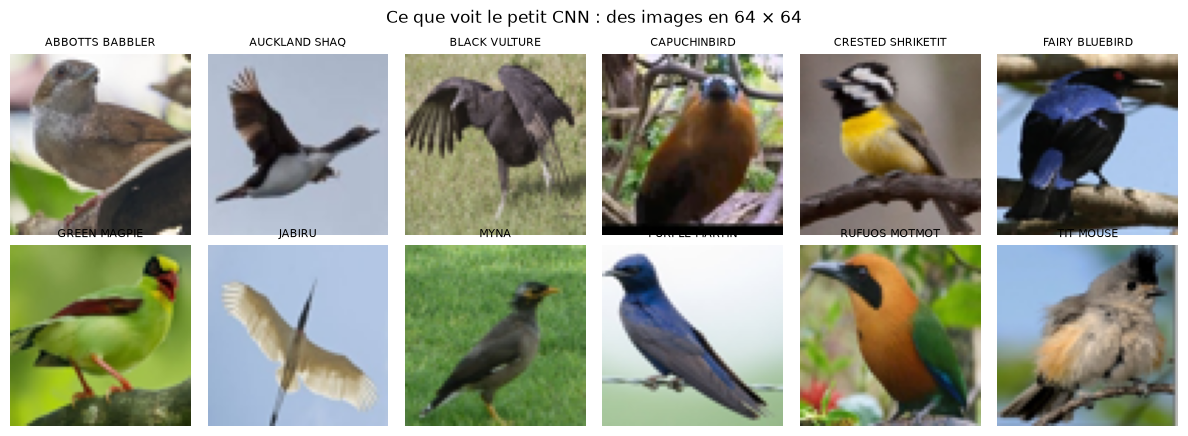

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for k, ax in enumerate(axes.flat):
    i = k * 7000
    ax.imshow(X_tr[i].permute(1, 2, 0))
    ax.set_title(CLASSES[y_tr[i]][:20], fontsize=8)
    ax.axis("off")
plt.suptitle("Ce que voit le petit CNN : des images en 64 × 64")
plt.tight_layout()
plt.show()

**Lecture :** en 64 × 64, on reconnaît encore la forme générale et les grandes zones de couleur, mais les détails fins du plumage (rayures, petites taches, la forme exacte du bec) sont en grande partie perdus. C'est un premier handicap pour distinguer des espèces proches.

## 2. Normaliser les pixels

Comme `Normalize` au TP7 (et le `StandardScaler` du TP1) : on recentre chaque canal de couleur autour de 0 avec un écart-type de 1. Les moyennes et écarts-types sont calculés **sur le train seulement**, puis appliqués tels quels à la validation.

In [4]:
MEAN = (X_tr.float() / 255).mean(dim=(0, 2, 3)).view(1, 3, 1, 1)
STD = (X_tr.float() / 255).std(dim=(0, 2, 3)).view(1, 3, 1, 1)
print("moyenne par canal (R, V, B) :", MEAN.flatten().numpy().round(3))
print("écart-type par canal        :", STD.flatten().numpy().round(3))

def prepare(xb):
    # uint8 [0, 255] -> float centré-réduit
    return (xb.float() / 255 - MEAN) / STD

moyenne par canal (R, V, B) : [0.474 0.469 0.396]
écart-type par canal        : [0.232 0.225 0.248]


## 3. Le modèle

On part du CNN du cours (convolution, ReLU, MaxPool, répétés) avec quatre adaptations, chacune pour une raison :

| Changement | Cours (Fashion-MNIST) | Ici | Pourquoi |
|---|---|---|---|
| Canaux en entrée | 1 (gris) | **3** (couleur) | La couleur des plumes est essentielle |
| Blocs de convolution | 2 | **4** (32, 64, 128, 256 filtres) | Des images plus grandes et 525 classes : il faut plus de motifs |
| `BatchNorm2d` après chaque convolution | non | **oui** | Garde les valeurs à une échelle stable d'une couche à l'autre : l'apprentissage est plus rapide et plus stable |
| Fin du réseau | `Flatten` + `Linear` | **`AdaptiveAvgPool2d(1)`** + `Dropout` + `Linear(256, 525)` | Fait la moyenne de chaque carte : beaucoup moins de paramètres, et le `Dropout` limite l'overfitting |

Les tailles : 64 → 32 → 16 → 8 → 4 après les quatre MaxPool, puis la moyenne donne 256 nombres par image (son **embedding**), puis 525 logits.

In [5]:
def block(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
            nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]

def make_cnn(n_classes=525):
    return nn.Sequential(
        *block(3, 32), *block(32, 64), *block(64, 128), *block(128, 256),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        nn.Dropout(0.3),
        nn.Linear(256, n_classes),
    )

count = lambda m: sum(p.numel() for p in m.parameters())
cnn = make_cnn()
x = torch.zeros(2, 3, SIZE, SIZE)
for layer in cnn:
    x = layer(x)
    if not isinstance(layer, (nn.ReLU, nn.BatchNorm2d)):
        print(f"{type(layer).__name__:<18}", list(x.shape))
print(f"\n{count(cnn):,} paramètres".replace(",", " "))

Conv2d             [2, 32, 64, 64]
MaxPool2d          [2, 32, 32, 32]
Conv2d             [2, 64, 32, 32]
MaxPool2d          [2, 64, 16, 16]
Conv2d             [2, 128, 16, 16]
MaxPool2d          [2, 128, 8, 8]
Conv2d             [2, 256, 8, 8]
MaxPool2d          [2, 256, 4, 4]
AdaptiveAvgPool2d  [2, 256, 1, 1]
Flatten            [2, 256]
Dropout            [2, 256]
Linear             [2, 525]

523 821 paramètres


## 4. La boucle d'entraînement

Même principe que le cours : Adam, `CrossEntropyLoss`, des batchs mélangés à chaque epoch. Deux ajouts :

- **Data augmentation** (slide 28), sur le train seulement : flip horizontal une fois sur deux, et un petit décalage aléatoire (on ajoute une bordure de 4 pixels puis on recoupe 64 × 64 au hasard). Le modèle voit des variantes à chaque epoch et ne peut pas apprendre les photos par cœur.
- **Learning rate en cosinus** : il descend doucement de 0,002 vers 0 au fil des epochs. Grands pas au début, petits pas à la fin (voir `EXPLICATIONS.md`).

À chaque epoch on note la loss et l'accuracy sur le train et la validation, pour tracer les courbes et repérer l'overfitting.

In [6]:
EPOCHS, BATCH, LR = 12, 128, 2e-3

def augment(xb):
    flip = torch.rand(len(xb)) < 0.5
    xb = torch.where(flip.view(-1, 1, 1, 1), xb.flip(3), xb)
    padded = F.pad(xb, (4, 4, 4, 4), mode="reflect")
    i, j = torch.randint(0, 9, (2,))
    return padded[:, :, i:i + SIZE, j:j + SIZE]

@torch.no_grad()
def evaluate(model, X, y, batch=512):
    model.eval()
    losses, correct, top5 = 0.0, 0, 0
    for k in range(0, len(X), batch):
        logits = model(prepare(X[k:k + batch]))
        yb = y[k:k + batch]
        losses += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
        top5 += (logits.topk(5, 1).indices == yb[:, None]).any(1).sum().item()
    return losses / len(X), correct / len(X), top5 / len(X)

def fit(model, epochs=EPOCHS):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    steps = epochs * ((len(X_tr) + BATCH - 1) // BATCH)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    hist = []
    for epoch in range(1, epochs + 1):
        model.train()
        t0, tot_loss, tot_ok = time.time(), 0.0, 0
        for idx in torch.randperm(len(X_tr)).split(BATCH):
            xb, yb = prepare(augment(X_tr[idx])), y_tr[idx]
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            tot_loss += loss.item() * len(idx)
            tot_ok += (logits.argmax(1) == yb).sum().item()
        va_loss, va_acc, va_top5 = evaluate(model, X_va, y_va)
        hist.append({"epoch": epoch, "train_loss": tot_loss / len(X_tr), "train_acc": tot_ok / len(X_tr),
                     "val_loss": va_loss, "val_acc": va_acc, "val_top5": va_top5,
                     "minutes": (time.time() - t0) / 60})
        h = hist[-1]
        print(f"epoch {epoch:>2} | train loss {h['train_loss']:.3f} acc {h['train_acc']:.3f} | "
              f"val loss {h['val_loss']:.3f} acc {h['val_acc']:.3f} top5 {h['val_top5']:.3f} | "
              f"{h['minutes']:.1f} min", flush=True)
    return pd.DataFrame(hist)

## 5. Entraîner (environ une heure sur ce processeur)

L'entraînement sauvegarde le modèle et son historique dans `outputs/`. Si le fichier existe déjà, on le recharge au lieu de tout recommencer : on peut relancer le notebook sans attendre une heure. Pour réentraîner, il suffit de mettre `RETRAIN = True`.

In [7]:
RETRAIN = False
ckpt = OUT / "petit_cnn.pt"

torch.manual_seed(42)
cnn = make_cnn()
if ckpt.exists() and not RETRAIN:
    saved = torch.load(ckpt)
    cnn.load_state_dict(saved["weights"])
    hist = pd.DataFrame(saved["history"])
    print("Modèle rechargé depuis", ckpt)
else:
    t0 = time.time()
    hist = fit(cnn)
    print(f"\nEntraînement total : {(time.time() - t0) / 60:.0f} min")
    torch.save({"weights": cnn.state_dict(), "history": hist.to_dict("records"),
                "classes": CLASSES, "size": SIZE,
                "mean": MEAN.flatten().tolist(), "std": STD.flatten().tolist()}, ckpt)
hist.round(3)

epoch  1 | train loss 4.895 acc 0.080 | val loss 3.913 acc 0.178 top5 0.430 | 5.4 min


epoch  2 | train loss 3.332 acc 0.277 | val loss 2.504 acc 0.419 top5 0.700 | 5.4 min


epoch  3 | train loss 2.615 acc 0.409 | val loss 1.834 acc 0.576 top5 0.802 | 5.5 min


epoch  4 | train loss 2.215 acc 0.491 | val loss 1.642 acc 0.618 top5 0.835 | 5.4 min


epoch  5 | train loss 1.966 acc 0.545 | val loss 1.387 acc 0.672 top5 0.868 | 5.3 min


epoch  6 | train loss 1.778 acc 0.583 | val loss 1.168 acc 0.723 top5 0.896 | 5.3 min


... (4 outputs left out)

epoch 11 | train loss 1.353 acc 0.677 | val loss 0.895 acc 0.789 top5 0.925 | 5.3 min


epoch 12 | train loss 1.331 acc 0.684 | val loss 0.895 acc 0.788 top5 0.925 | 5.4 min



Entraînement total : 65 min


,epoch,train_loss,train_acc,val_loss,val_acc,val_top5,minutes
0,1,4.895,0.080,3.913,0.178,0.430,5.360
1,2,3.332,0.277,2.504,0.419,0.700,5.437
2,3,2.615,0.409,1.834,0.576,0.802,5.527
3,4,2.215,0.491,1.642,0.618,0.835,5.359
4,5,1.966,0.545,1.387,0.672,0.868,5.347
5,6,1.778,0.583,1.168,0.723,0.896,5.346
6,7,1.643,0.614,1.125,0.734,0.904,5.317
7,8,1.534,0.637,1.026,0.765,0.914,5.331
8,9,1.448,0.656,0.974,0.761,0.920,5.400
9,10,1.383,0.672,0.917,0.783,0.924,5.372


## 6. Les courbes : apprend-il ? surapprend-il ?

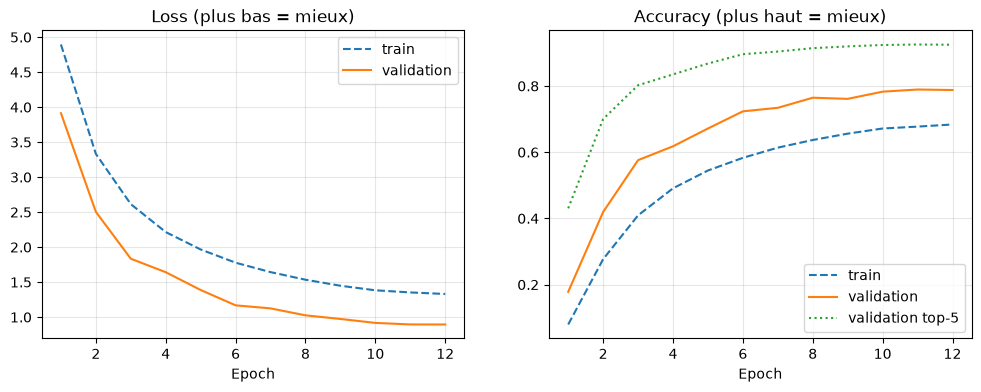

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.epoch, hist.train_loss, "--", label="train")
axes[0].plot(hist.epoch, hist.val_loss, label="validation")
axes[0].set_title("Loss (plus bas = mieux)")
axes[1].plot(hist.epoch, hist.train_acc, "--", label="train")
axes[1].plot(hist.epoch, hist.val_acc, label="validation")
axes[1].plot(hist.epoch, hist.val_top5, ":", label="validation top-5")
axes[1].set_title("Accuracy (plus haut = mieux)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)
plt.show()

**Lecture des courbes.**

- Les deux pertes descendent jusqu'au bout et la validation ne remonte jamais. Il n'y a donc **pas de sur-apprentissage**.
- L'accuracy de train (68 %) est *plus basse* que celle de validation (79 %). Ce n'est pas un bug : pendant l'entraînement, le modèle voit des images retournées et décalées et le dropout lui « cache » des neurones, ce qui rend l'exercice plus dur. En validation, il voit les images propres, sans dropout.
- Les dernières epochs ne gagnent presque plus rien (78,3 → 78,9 → 78,8 %). Le modèle a atteint **sa limite** : il est trop petit et ses images de 64 × 64 sont trop floues pour aller beaucoup plus loin. C'est du **sous-apprentissage** : il faudrait plus de capacité, pas plus de régularisation.

## 7. Le résultat, comparé à la baseline

In [9]:
va_loss, va_acc, va_top5 = evaluate(cnn, X_va, y_va)
n = len(y_va)
margin = 1.96 * (va_acc * (1 - va_acc) / n) ** 0.5   # marge d'erreur à 95 %
print(f"Baseline (classe majoritaire) : {1/525:.2%}")
print(f"Petit CNN, accuracy           : {va_acc:.2%}  (± {margin:.1%})")
print(f"Petit CNN, top-5              : {va_top5:.2%}")
print(f"Soit {va_acc * 525:.0f} fois mieux que la baseline")

Baseline (classe majoritaire) : 0.19%
Petit CNN, accuracy           : 78.78%  (± 1.6%)
Petit CNN, top-5              : 92.46%
Soit 414 fois mieux que la baseline


**La marge d'erreur.** La validation n'a que 2 625 images. Si on refaisait la mesure sur 2 625 autres photos, le score bougerait un peu, par hasard. Le « ± » donne l'ordre de grandeur de ce hasard (intervalle de confiance à 95 %). Deux modèles dont les scores diffèrent de moins que cette marge ne peuvent pas être départagés.

**Est-ce un bon score ?** Pour un réseau de 0,5 million de paramètres, parti de zéro, entraîné en 65 minutes sur un portable sans carte graphique, avec des images 12 fois plus petites que les originales : **oui, c'est très correct**. Il trouve la bonne espèce 4 fois sur 5, et elle est dans ses 5 premières propositions 92 fois sur 100.

Mais pour une application réelle, c'est insuffisant : il se trompe sur **une photo sur cinq**. Le transfer learning devrait viser environ 99 %, soit 20 fois moins d'erreurs.

## 8. Quelles espèces réussit-il, lesquelles rate-t-il ?

Le **recall** d'une espèce : sur ses 5 photos de validation, combien sont reconnues. Avec seulement 5 photos, c'est très grossier (0, 20, 40, 60, 80 ou 100 %), on regarde donc surtout les extrêmes.

In [10]:
cnn.eval()
with torch.no_grad():
    probs = torch.cat([F.softmax(cnn(prepare(X_va[k:k + 512])), 1) for k in range(0, len(X_va), 512)])
pred = probs.argmax(1)
conf = probs.max(1).values

per_class = pd.DataFrame({"espece": [CLASSES[i] for i in y_va], "ok": (pred == y_va).numpy()})
recall = per_class.groupby("espece")["ok"].mean()
print("Répartition du recall entre les 525 espèces :")
print((recall * 100).round().astype(int).value_counts().sort_index(ascending=False).rename("espèces").to_string())
print("\nExemples d'espèces reconnues 5 fois sur 5 :", ", ".join(recall[recall == 1].index[:8]))
print("Exemples d'espèces jamais reconnues        :", ", ".join(recall[recall == 0].index[:8]))
print("\nPLUSH CRESTED JAY (le faux indice de taille) :", f"{recall['PLUSH CRESTED JAY']:.0%}")

Répartition du recall entre les 525 espèces :
ok
100    205
80     159
60     108
40      34
20      15
0        4

Exemples d'espèces reconnues 5 fois sur 5 : AMERICAN GOLDFINCH, ANIANIAU, ANNAS HUMMINGBIRD, ANTBIRD, ANTILLEAN EUPHONIA, ARARIPE MANAKIN, ASIAN GREEN BEE EATER, AVADAVAT
Exemples d'espèces jamais reconnues        : BROWN HEADED COWBIRD, IMPERIAL SHAQ, NORTHERN BEARDLESS TYRANNULET, TRICOLORED BLACKBIRD

PLUSH CRESTED JAY (le faux indice de taille) : 100%


### Les confusions les plus fréquentes

In [11]:
pairs = pd.DataFrame({"vraie": [CLASSES[i] for i in y_va], "predite": [CLASSES[i] for i in pred]})
pairs = pairs[pairs.vraie != pairs.predite]
pairs.value_counts().head(10).rename("fois").to_frame()

,,fois
vraie,predite,
PURPLE FINCH,HOUSE FINCH,3
AMERICAN BITTERN,JACK SNIPE,2
APAPANE,IWI,2
ASHY STORM PETREL,RAZORBILL,2
BEARDED BARBET,DUSKY LORY,2
BLACK FRANCOLIN,SNOW PARTRIDGE,2
FASCIATED WREN,CACTUS WREN,2
GILDED FLICKER,NORTHERN FLICKER,2
GREAT XENOPS,CINNAMON ATTILA,2


## 9. Six erreurs où le modèle était le plus sûr de lui

Comme au TP7 : ce sont les plus instructives. À gauche la photo de validation, à droite une photo de train de l'espèce que le modèle a répondue.

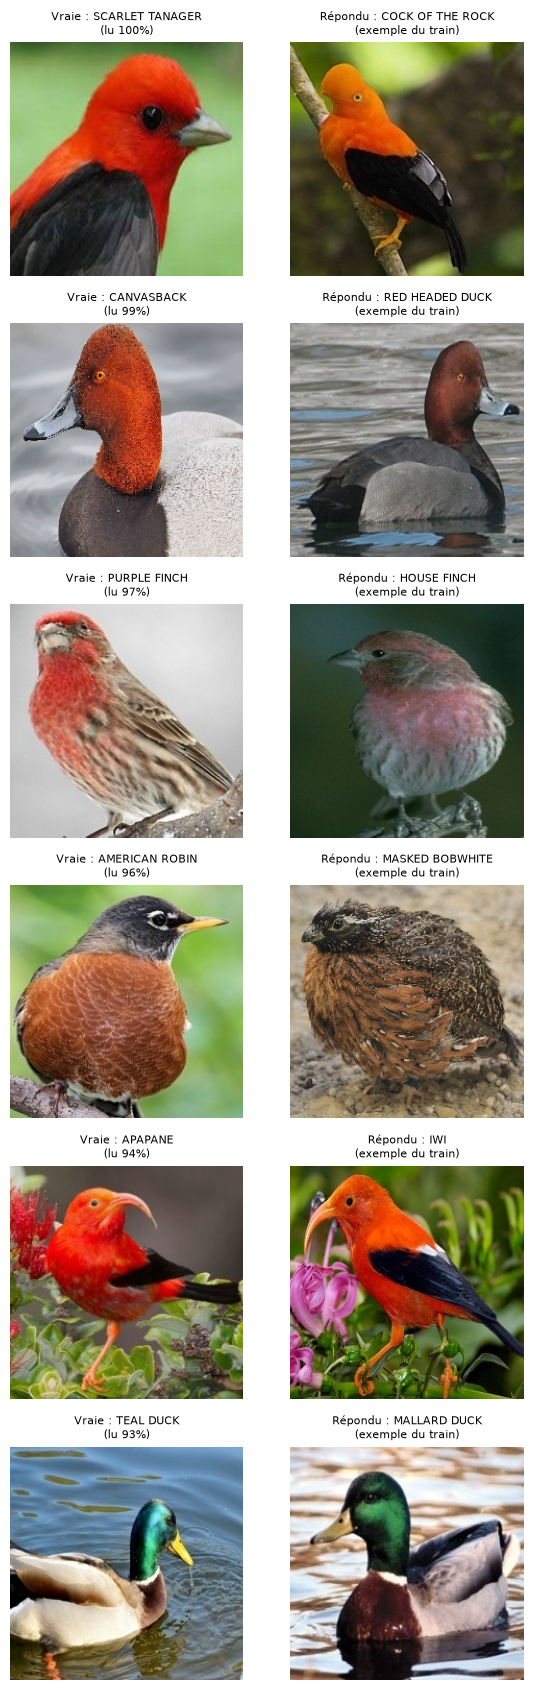

In [12]:
wrong = (pred != y_va).nonzero().squeeze(1)
worst = wrong[conf[wrong].argsort(descending=True)][:6]
train_meta = meta[meta.partition == "train"]
fig, axes = plt.subplots(6, 2, figsize=(6, 17))
for row, i in zip(axes, worst):
    true_c, pred_c = CLASSES[y_va[i]], CLASSES[pred[i]]
    val_path = meta[meta.partition == "val"].iloc[i.item()]["chemin"]
    other = train_meta[train_meta.espece == pred_c].iloc[0]["chemin"]
    row[0].imshow(Image.open(ROOT / val_path))
    row[0].set_title(f"Vraie : {true_c}\n(lu {conf[i]:.0%})", fontsize=8)
    row[1].imshow(Image.open(ROOT / other))
    row[1].set_title(f"Répondu : {pred_c}\n(exemple du train)", fontsize=8)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()

**Ce que montrent ces erreurs.**

- **Scarlet Tanager → Cock of the Rock, American Robin → Masked Bobwhite** : des oiseaux très différents, mais avec les mêmes **couleurs** (rouge vif et noir ; poitrine orangée et tachetée). À 64 × 64 pixels, la forme du bec et les détails disparaissent : le petit CNN se fie surtout aux taches de couleur.
- **Purple Finch → House Finch, Canvasback → Redhead** : des espèces réellement proches, que même un humain confond. Ce sont des erreurs « honnêtes ».
- **Deux étiquettes suspectes.** La photo étiquetée *TEAL DUCK* montre visiblement un colvert mâle (*MALLARD*) : tête verte, bec jaune, collier blanc. Et la photo étiquetée *APAPANE* a le long bec courbé couleur saumon de l'*IIWI*. Dans ces deux cas, **c'est peut-être le modèle qui a raison et le dataset qui se trompe**. On le gardera en tête : une partie des « erreurs » des meilleurs modèles viendra d'étiquettes fausses, qu'aucun modèle ne peut réussir.

## Bilan de l'étape 3


| | Accuracy de validation | Top-5 |
|---|---|---|
| Baseline (classe majoritaire) | 0,19 % | — |
| Petit CNN (64 × 64, partie de zéro) | **78,8 % ± 1,6** | 92,5 % |

**Ce qu'on retient :**

1. Un réseau de convolutions apprend vraiment : on passe de 0,2 % à 79 %, soit 414 fois mieux qu'au hasard.
2. Il plafonne parce qu'il part de zéro avec peu de capacité et des images basse résolution. Il ne sur-apprend pas, il manque de « savoir ».
3. Ses erreurs viennent surtout de la couleur et des détails fins perdus. C'est exactement ce qu'un réseau **pré-entraîné** sur des millions d'images, à pleine résolution, sait mieux faire.
4. Le dataset contient probablement quelques étiquettes fausses. Il faudra les compter avant d'interpréter le score final.

**Étape suivante :** le transfer learning (étapes 4 et 5), sur carte graphique RunPod.